In [1]:
!pip install numpy==2.2.0
!pip install pandas==2.2.3
!pip install scikit-learn==1.6.0
!pip install matplotlib==3.9.3

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
%matplotlib inline


In [3]:
url= "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%202/data/FuelConsumptionCo2.csv"

In [4]:
df=pd.read_csv(url)

In [5]:
# verify successful load with some randomly selected records
df.sample(1000)

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
449,2014,GMC,SAVANA 2500 PASSENGER,VAN - PASSENGER,6.0,8,A6,E,30.0,20.4,25.7,11,411
543,2014,INFINITI,QX60 HYBRID AWD,SUV - STANDARD,2.5,4,AV,X,8.8,8.2,8.5,33,196
812,2014,MINI,JOHN COOPER WORKS PACEMAN ALL4,COMPACT,1.6,4,A6,Z,10.0,7.8,9.0,31,207
689,2014,MASERATI,GHIBLI AWD,MID-SIZE,3.0,6,AS8,Z,15.2,9.6,12.7,22,292
776,2014,MERCEDES-BENZ,SLK 55 AMG,TWO-SEATER,5.5,8,AS7,Z,12.3,8.7,10.7,26,246
...,...,...,...,...,...,...,...,...,...,...,...,...,...
908,2014,PORSCHE,PANAMERA TURBO EXECUTIVE,FULL-SIZE,4.8,8,AM7,Z,15.4,9.8,12.9,22,297
856,2014,NISSAN,ROGUE AWD,SUV - SMALL,2.5,4,AV,X,9.5,7.4,8.6,33,198
907,2014,PORSCHE,PANAMERA TURBO,FULL-SIZE,4.8,8,AM7,Z,15.3,9.7,12.8,22,294
929,2014,SCION,FR-S,MINICOMPACT,2.0,4,AS6,Z,9.6,7.0,8.4,34,193


In [6]:
df.describe()

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
count,1067.0,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000
mean,2014.0,3.346298,5.794752,13.296532,9.474602,11.580881,26.441425,256.228679
std,0.0,1.415895,1.797447,4.101253,2.794510,3.485595,7.468702,63.372304
min,2014.0,1.000000,3.000000,4.600000,4.900000,4.700000,11.000000,108.000000
25%,2014.0,2.000000,4.000000,10.250000,7.500000,9.000000,21.000000,207.000000
50%,2014.0,3.400000,6.000000,12.600000,8.800000,10.900000,26.000000,251.000000
75%,2014.0,4.300000,8.000000,15.550000,10.850000,13.350000,31.000000,294.000000
max,2014.0,8.400000,12.000000,30.200000,20.500000,25.800000,60.000000,488.000000


In [7]:
# visualization features
cdf = df[['ENGINESIZE','CYLINDERS','FUELCONSUMPTION_COMB','CO2EMISSIONS']]
cdf.sample(9)


,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_COMB,CO2EMISSIONS
168,3.6,6,12.8,294
511,2.0,4,11.5,264
878,3.8,6,10.8,248
633,6.5,12,18.3,421
958,2.5,4,9.0,207
148,2.4,4,8.2,189
10,2.4,4,9.8,225
70,4.0,8,13.9,320
1007,5.7,8,16.2,373


Text(0, 0.5, 'Emission')

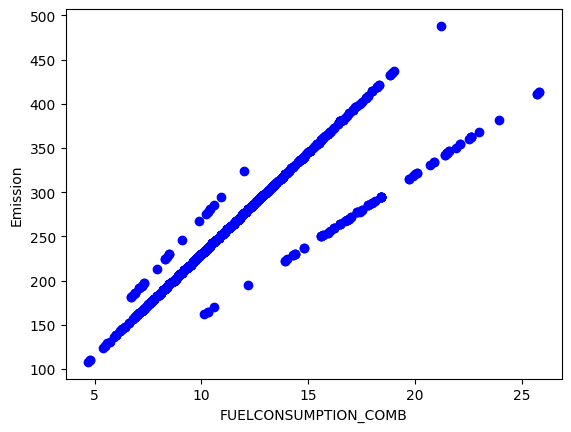

In [8]:
plt.scatter(cdf.FUELCONSUMPTION_COMB, cdf.CO2EMISSIONS,  color='blue')
plt.xlabel("FUELCONSUMPTION_COMB")
plt.ylabel("Emission")

In [9]:
print(df.columns)

Index(['MODELYEAR', 'MAKE', 'MODEL', 'VEHICLECLASS', 'ENGINESIZE', 'CYLINDERS',
       'TRANSMISSION', 'FUELTYPE', 'FUELCONSUMPTION_CITY',
       'FUELCONSUMPTION_HWY', 'FUELCONSUMPTION_COMB',
       'FUELCONSUMPTION_COMB_MPG', 'CO2EMISSIONS'],
      dtype='object')


In [10]:
# extract the input feature and lable from the dataset
X = cdf.ENGINESIZE.to_numpy()
y = cdf.CO2EMISSIONS.to_numpy()

In [11]:
# here we create and test datasets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [12]:
# the outputs are one-dimensional NumPY arrays or Vectors
type(X_train), np.shape(X_train), np.shape(X_train)

(numpy.ndarray, (853,), (853,))

In [13]:
# using scikit-learn to build a linear regression model

from sklearn import linear_model

# create a model object
regressor = linear_model.LinearRegression()

# train the model on the training data
# X_train is a 1-D array but sklearn models expect a 2D array as input for the training data, with shape (n_observations, n_features).
# So we need to reshape it. We can let it infer the number of observations using '-1'.
regressor.fit(X_train.reshape(-1, 1), y_train)

# Print the coefficients
print ('Coefficients: ', regressor.coef_[0]) # with simple linear regression there is only one coefficient, here we extract it from the 1 by 1 array.
print ('Intercept: ',regressor.intercept_)

Coefficients:  38.99297872443403
Intercept:  126.28970217408735


Text(0, 0.5, 'Emission')

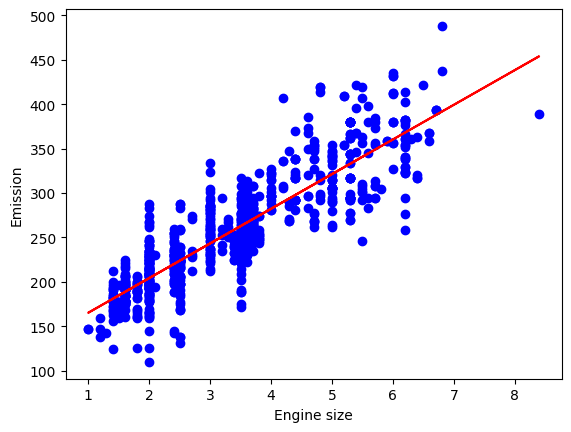

In [14]:
# visualisation of the models output
plt.scatter(X_train, y_train,  color='blue')
plt.plot(X_train, regressor.coef_ * X_train + regressor.intercept_, '-r')
plt.xlabel("Engine size")
plt.ylabel("Emission")